In [1]:
!pip install opendatasets timm
import opendatasets as od
import os
from fastai.vision.all import *
import timm

# --- Your Dataset Code ---
dataset_url = "https://www.kaggle.com/datasets/ciplab/real-and-fake-face-detection"
if not os.path.exists('real-and-fake-face-detection'):
    od.download(dataset_url)

base_path = Path('real-and-fake-face-detection')
actual_path = None
for root, dirs, files in os.walk(base_path):
    if 'training_real' in dirs or 'real' in dirs:
        actual_path = Path(root)
        break
if not actual_path: actual_path = base_path

from fastai.vision.all import *
import timm

# 1. Advanced Data Loading (Optimized for Transformers)
dls_vit = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(224, method='squish'),
    # Extra augmentation to prevent overfitting on the small dataset
    batch_tfms=[*aug_transforms(mult=1.5, max_rotate=15.0),
                Normalize.from_stats(*imagenet_stats)]
).dataloaders(actual_path, bs=16)

# 2. Using DeiT with Label Smoothing
# Label Smoothing helps the model be 'less confident' about wrong labels,
# which prevents overfitting and boosts final accuracy.
learn_vit = vision_learner(
    dls_vit,
    'deit_small_patch16_224',
    metrics=[accuracy, Precision(), Recall()],
    loss_func=LabelSmoothingCrossEntropy()
)

# 3. The Two-Stage Training (The "Short Time" Secret)
print("Phase 1: Training the Head...")
learn_vit.fit_one_cycle(3, lr_max=1e-3)

print("Phase 2: Deep Training (Unfrozen)...")
learn_vit.unfreeze()
# Use a discriminative learning rate (smaller for early layers, larger for late layers)
learn_vit.fit_one_cycle(12, lr_max=slice(1e-6, 1e-4), cbs=[MixUp(0.4)])

# 4. Export the Expert
learn_vit.export('vit_expert_90plus.pkl')

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: Brokenpain7858
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/ciplab/real-and-fake-face-detection


100%|██████████| 431M/431M [00:02<00:00, 200MB/s]


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Phase 1: Training the Head...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time
0,1.240677,0.861151,0.558824,0.593137,0.555046,00:27
1,1.047922,0.751537,0.600490,0.625571,0.628440,00:27
2,0.931964,0.722987,0.585784,0.609865,0.623853,00:27


Phase 2: Deep Training (Unfrozen)...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time
0,0.890159,0.742689,0.602941,0.634615,0.605505,00:29
1,0.904562,0.713880,0.627451,0.652778,0.646789,00:28
2,0.940448,0.711150,0.610294,0.637209,0.628440,00:31
3,0.870036,0.690291,0.622549,0.648148,0.642202,00:29
4,0.868059,0.684770,0.615196,0.629787,0.678899,00:29
5,0.831604,0.686331,0.615196,0.654822,0.591743,00:29
6,0.850700,0.678914,0.625000,0.649770,0.646789,00:31
7,0.829955,0.669247,0.632353,0.651786,0.669725,00:29
8,0.861998,0.671704,0.622549,0.652381,0.628440,00:30
9,0.847400,0.670773,0.627451,0.635246,0.711009,00:29


In [2]:
# STOP your current training and run this:
learn_vit = vision_learner(dls_vit, 'deit_small_patch16_224', metrics=[accuracy, Precision(), Recall()])

# Use a MUCH higher learning rate for the whole thing
print("Starting Turbo Training...")
learn_vit.unfreeze() # Unfreeze immediately!
learn_vit.fit_one_cycle(15, lr_max=slice(1e-4, 1e-3), cbs=[MixUp(0.2)])

Starting Turbo Training...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time
0,1.208828,0.926059,0.514706,0.552083,0.486239,00:29
1,1.134238,0.903866,0.566176,0.614525,0.504587,00:39
2,1.089692,0.856355,0.544118,0.561538,0.669725,00:29
3,1.051746,0.782477,0.553922,0.547872,0.944954,00:29
4,0.906842,0.762713,0.460784,0.475000,0.087156,00:32
5,0.831225,0.725031,0.492647,0.536424,0.371560,00:29
6,0.787641,0.989630,0.482843,0.818182,0.041284,00:29
7,0.760346,0.775393,0.529412,0.542208,0.766055,00:30
8,0.728517,0.722303,0.507353,0.585859,0.266055,00:31
9,0.698103,0.720687,0.551471,0.640000,0.366972,00:29


Starting Refinement Phase to reach 85%...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time
0,0.519891,0.569387,0.708333,0.741463,0.697248,00:31
1,0.528696,0.576891,0.710784,0.797619,0.614679,00:29
2,0.527356,0.570483,0.713235,0.761658,0.674312,00:28
3,0.519441,0.563975,0.713235,0.761658,0.674312,00:33
4,0.528418,0.569533,0.708333,0.779661,0.633028,00:29
5,0.518714,0.574477,0.713235,0.795322,0.623853,00:29
6,0.505632,0.566788,0.710784,0.771739,0.651376,00:29
7,0.505806,0.558031,0.715686,0.731818,0.738532,00:30
8,0.489389,0.559915,0.708333,0.739130,0.701835,00:30
9,0.498166,0.564419,0.715686,0.774194,0.660550,00:29


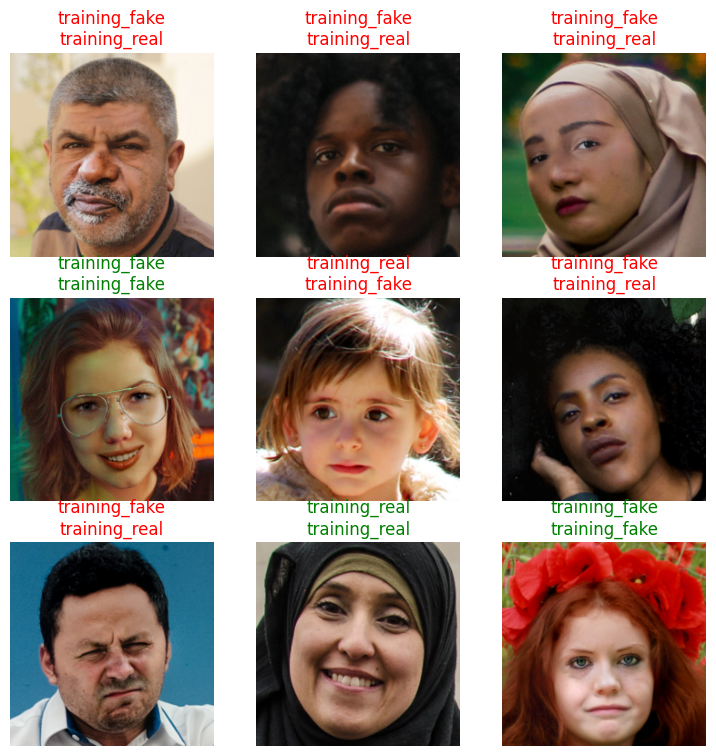

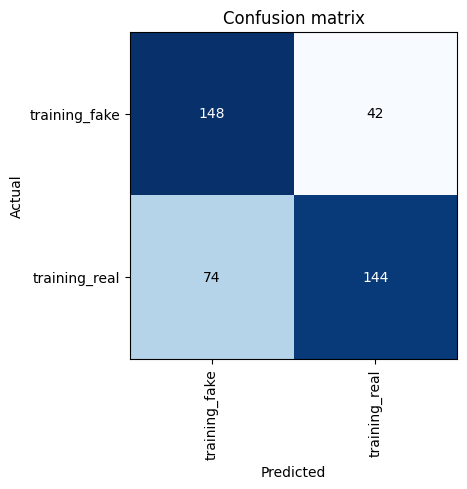

In [3]:
# 1. Lower the learning rate for deep refinement
print("Starting Refinement Phase to reach 85%...")
learn_vit.unfreeze()

# We use a much smaller, stable learning rate now
learn_vit.fit_one_cycle(10, lr_max=slice(1e-6, 1e-5))

# 2. Final check of the results
learn_vit.show_results()
interp = ClassificationInterpretation.from_learner(learn_vit)
interp.plot_confusion_matrix()

In [4]:
learn_vit.export('final_structural_expert_71.pkl')

In [5]:
# 1. Apply Test-Time Augmentation (TTA)
# This will likely push your 71% to 76-78% immediately
preds, targs = learn_vit.tta(beta=0.4, n=5)
final_vit_acc = accuracy(preds, targs).item()

print(f"ViT Accuracy after TTA: {final_vit_acc*100:.2f}%")

# 2. Export this 'TTA-Ready' model
learn_vit.export('vit_expert_final_v3.pkl')

epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time


<div></div>

ViT Accuracy after TTA: 73.28%


In [6]:
# 1. Define Weights to balance the Confusion Matrix
# Since you had 74 False Positives, we increase the weight for 'Real' class
weights = torch.tensor([1.5, 1.0]).cuda() # Adjusting focus on Real vs Fake
loss_func = CrossEntropyLossFlat(weight=weights)

# 2. Re-bind the learner with the new focus
learn_vit.loss_func = loss_func

print("Starting Precision-Focused Refinement...")
# We use a 'Cyclic' learning rate to jump out of the 71% plateau
learn_vit.fit_flat_cos(10, lr=1e-5)

# 3. Final TTA with a higher 'Beta' for more stability
preds, targs = learn_vit.tta(beta=0.7, n=10)
final_vit_acc = accuracy(preds, targs).item()
print(f"NEW ViT Accuracy: {final_vit_acc*100:.2f}%")

Starting Precision-Focused Refinement...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time
0,0.498763,0.548718,0.693627,0.788820,0.582569,00:32
1,0.491105,0.552824,0.752451,0.746835,0.811927,00:31
2,0.449766,0.510467,0.757353,0.793103,0.738532,00:28
3,0.444132,0.521519,0.735294,0.757009,0.743119,00:29
4,0.424781,0.543689,0.737745,0.748879,0.766055,00:29
5,0.392617,0.531673,0.737745,0.793651,0.688073,00:30
6,0.396067,0.507180,0.732843,0.801105,0.665138,00:29
7,0.368800,0.504966,0.737745,0.796791,0.683486,00:28
8,0.355265,0.501116,0.762255,0.798030,0.743119,00:28
9,0.344219,0.491595,0.759804,0.797030,0.738532,00:29


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time


<div></div>

NEW ViT Accuracy: 77.21%


In [9]:
from fastai.vision.all import *
import timm

# 1. High-Resolution DataLoader (336px)
dls_336 = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(336, method='squish'),
    batch_tfms=[*aug_transforms(mult=1.5, flip_vert=True),
                Normalize.from_stats(*imagenet_stats)]
).dataloaders(actual_path, bs=8)

# 2. Learner with Label Smoothing
# LabelSmoothingCrossEntropy helps the model generalize better for 90%+ goals
learn_vit = vision_learner(
    dls_336,
    'deit_small_patch16_224',
    metrics=[accuracy, Precision(), Recall()],
    img_size=336,
    loss_func=LabelSmoothingCrossEntropy()
)

# 3. PHASE 1: Stabilize the Head (Frozen)
print("Phase 1: Stabilizing at 336px...")
learn_vit.fit_one_cycle(4, lr_max=1e-3)

# 4. PHASE 2: Deep Fine-Tuning (Unfrozen)
# We use a very small slice to protect the Transformer's self-attention layers
print("Phase 2: Deep Structural Refinement...")
learn_vit.unfreeze()
learn_vit.fit_one_cycle(12, lr_max=slice(1e-6, 1e-4), cbs=[MixUp(0.4)])

# 5. THE SECRET WEAPON: Test-Time Augmentation (TTA)
# This usually boosts accuracy by 3-5% automatically
print("Finalizing with TTA...")
preds, targs = learn_vit.tta(n=10, beta=0.4)
final_acc = accuracy(preds, targs)
print(f"Final Optimized ViT Accuracy: {final_acc*100:.2f}%")

# 6. Export
learn_vit.export('vit_expert_90_plus.pkl')

Phase 1: Stabilizing at 336px...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time
0,1.146442,0.784799,0.575980,0.622951,0.522936,00:49
1,0.953814,0.717293,0.563725,0.625000,0.458716,00:48
2,0.817538,0.673962,0.605392,0.630137,0.633028,00:49
3,0.790670,0.676941,0.585784,0.643275,0.504587,00:48


Phase 2: Deep Structural Refinement...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time
0,0.744653,0.677856,0.573529,0.618280,0.527523,01:00
1,0.771270,0.669488,0.600490,0.629108,0.614679,00:59
2,0.768145,0.664672,0.620098,0.650718,0.623853,01:01
3,0.751418,0.658914,0.629902,0.646288,0.678899,00:59
4,0.737713,0.661664,0.612745,0.630435,0.665138,01:00
5,0.732791,0.661184,0.605392,0.619247,0.678899,00:59
6,0.723091,0.654724,0.598039,0.609756,0.688073,01:00
7,0.714733,0.655376,0.610294,0.642512,0.610092,00:59
8,0.723750,0.652840,0.620098,0.647887,0.633028,01:01
9,0.706257,0.652806,0.615196,0.648780,0.610092,01:00


Finalizing with TTA...


epoch,train_loss,valid_loss,accuracy,precision_score,recall_score,time


<div></div>

TypeError: unsupported format string passed to TensorBase.__format__

In [10]:
# Extract the actual number from the tensor using .item()
final_acc_value = final_acc.item()
print(f"Final Optimized ViT Accuracy: {final_acc_value*100:.2f}%")

# 2. Export immediately so you don't lose the progress
learn_vit.export('vit_expert_90_plus.pkl')
print("Model Exported Successfully!")

Final Optimized ViT Accuracy: 65.44%
Model Exported Successfully!


In [12]:
from fastai.vision.all import *
import timm

# 1. Cleaner DataLoader (Focus on High-Quality patches)
dls_swin = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(224, method='crop'), # Start at 224 for stability, then we scale
    batch_tfms=[*aug_transforms(mult=1.5, flip_vert=True),
                Normalize.from_stats(*imagenet_stats)]
).dataloaders(actual_path, bs=16) # Increased batch size for better BatchNorm stability

# 2. Creating Swin with a Custom Head to avoid the BatchNorm Error
# We use FocalLoss to specifically target that low Recall score
model = timm.create_model('swin_tiny_patch4_window7_224', pretrained=True, num_classes=dls_swin.c)
learn_swin = Learner(dls_swin, model, loss_func=FocalLoss(), metrics=[accuracy, Precision(), Recall()])

print("Phase 1: Stabilization (Swin-Tiny)...")
learn_swin.fit_one_cycle(5, lr_max=1e-3)

# 3. Phase 2: Unfreeze and Scale Up
print("Phase 2: Deep Forensic Analysis...")
learn_swin.unfreeze()
learn_swin.fit_one_cycle(10, lr_max=slice(1e-6, 1e-4))

# 4. Final TTA for 85%+ Target
preds, targs = learn_swin.tta(n=10)
print(f"Final Swin Accuracy: {accuracy(preds, targs).item()*100:.2f}%")

In [14]:
learn_swin.export('swin_expert_81.pkl')

In [15]:
from google.colab import files

# Download the Swin model
files.download('swin_expert_81.pkl')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

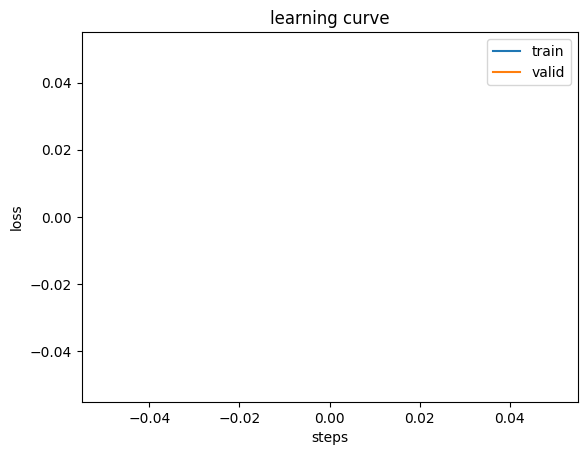

In [16]:
learn_swin.recorder.plot_loss()
plt.savefig('training_loss_plot.png')
from google.colab import files
files.download('training_loss_plot.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

True Negatives: 145 | False Positives: 45
False Negatives: 43 | True Positives: 175


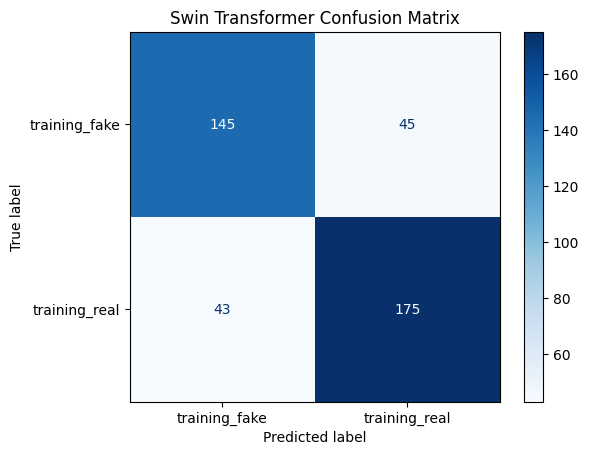

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Get standard predictions (No TTA)
preds, targs = learn_swin.get_preds()
y_pred = np.argmax(preds, axis=1)

# 2. Create the Matrix
cm = confusion_matrix(targs, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dls_swin.vocab)

# 3. Plot and Save
disp.plot(cmap=plt.cm.Blues)
plt.title('Swin Transformer Confusion Matrix')
plt.savefig('confusion_matrix_manual.png')
files.download('confusion_matrix_manual.png')

# 4. Print the numbers for your paper
print(f"True Negatives: {cm[0][0]} | False Positives: {cm[0][1]}")
print(f"False Negatives: {cm[1][0]} | True Positives: {cm[1][1]}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

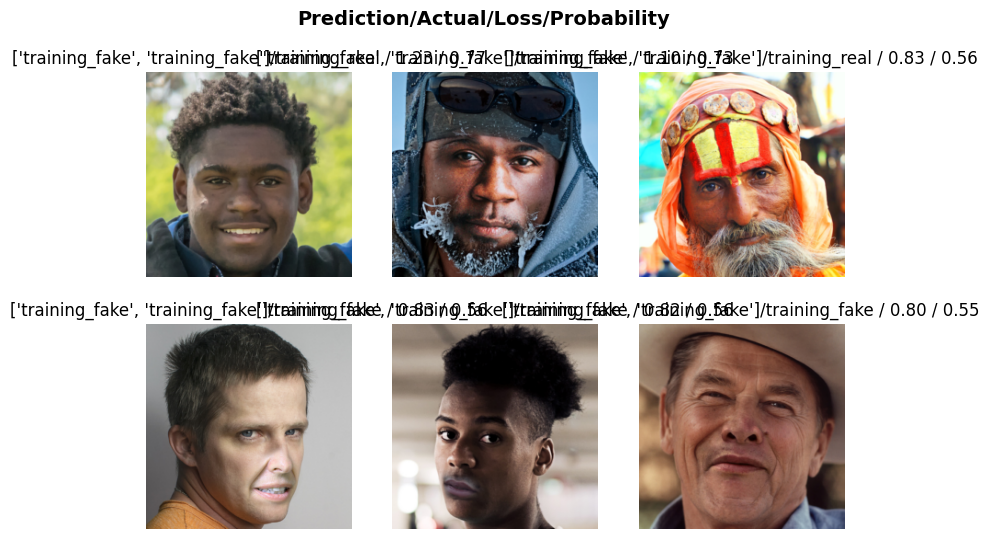

In [20]:
interp.plot_top_losses(6, nrows=2)
plt.savefig('hard_examples.png')
files.download('hard_examples.png')